# Run last cell first!

In [2]:
import math

import numpy as np
import matplotlib.pyplot as plt
import qiskit

import bosonic_qiskit
from qiskit.circuit import Parameter
from qiskit_aer import AerSimulator
from qiskit_aer.primitives import EstimatorV2 as Estimator
from qiskit.quantum_info import SparsePauliOp
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_aer.noise import (
    NoiseModel,
    QuantumError,
    ReadoutError,
    depolarizing_error,
    pauli_error,
    thermal_relaxation_error,
)
from qiskit.circuit import Parameter
from IPython.display import display

# Simulation of the Jaynes-Cummings Hamiltonian on bosonic hardware

The Hamiltonian is
$H=\omega_C a^\dagger a + \frac{\omega_A}{2}\sigma^z + \lambda \sigma^z (a^\dagger + a)$
</br></br>
We simulate the trotterized time evolution under this Hamiltonian  by implementing each term in $U_L=e^{-i \omega_C a^\dagger a t}$, $U_M=e^{-i \omega_A \sigma^z t/2}$ and $U_{LM}=e^{-i \lambda \sigma^z (a^\dagger + a) t}$ individually.

In [3]:
# Define Hamiltonian parameters
omega_A = 1
omega_C = 1
lam = 0.1

## Dynamics with $|\uparrow,0 \rangle$ initial state

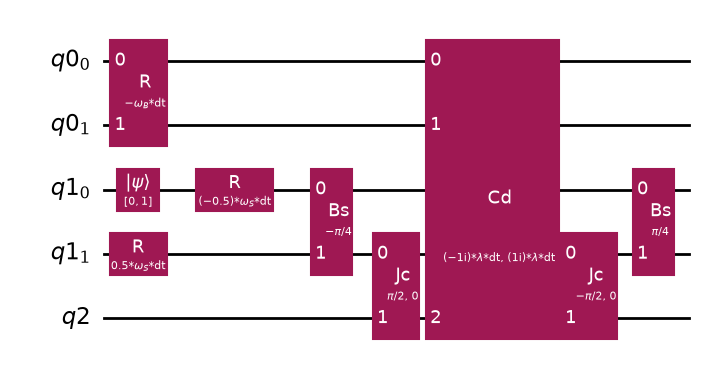

In [4]:
# Define computational parameters 

num_qubits_per_qumode = 2 # Cutoff of the qumode's Fock space: 2^num_qubits_per_qumode
t_tot = 2*np.pi/lam # total time 
N = 50 # number of sampling time steps
dt = 1.0 #t_tot/N # timestep for Trotter
sampling_t_list = np.linspace(0, t_tot, N+1, endpoint = True)

# Create new circuit
boson = bosonic_qiskit.QumodeRegister(num_qumodes=1, num_qubits_per_qumode=num_qubits_per_qumode) # qumode for the boson
spin = bosonic_qiskit.QumodeRegister(num_qumodes=2, num_qubits_per_qumode=1) # 2 qumodes for dual rail encoding of the spin. spin[0]: up, spin[1]: down
ancilla = qiskit.QuantumRegister(1) # Ancilla qubit needed for implementing the U_{LM}


circuit = bosonic_qiskit.CVCircuit(boson,spin,ancilla)

# Initialize state to the upper state of the spin
circuit.cv_initialize(1, spin[0])


# Define matrices of the observables
I_boson = circuit.ops.get_eye(boson.cutoff).toarray()
I_ancilla = circuit.ops.get_eye(2).toarray()
I_2 = np.eye(2)
n_2 = np.diag([0, 1])
s_minus_2 = np.array([[0, 1], [0, 0]])
s_plus_2 = np.array([[0, 0], [1, 0]])
sigmaz_spin =  np.kron(I_2, n_2) - np.kron(n_2, I_2)
sigmax_spin =  np.kron(s_minus_2, s_plus_2) + np.kron(s_plus_2, s_minus_2)
sigmaz = np.kron(I_ancilla, np.kron(sigmaz_spin, I_boson))
sigmax = np.kron(I_ancilla, np.kron(sigmax_spin, I_boson))


# Pretty print circuit 
circuit_print = circuit.copy()
eiht(circuit_print, boson, spin, ancilla, Parameter('$\omega_S$'), Parameter('$\omega_B$'), Parameter('$\lambda$'), Parameter('dt'))
fig = circuit_print.draw(output="mpl")
display(fig)

# timestep list for each sampling point
dt_list = []
for t in sampling_t_list:
    li = [dt for i in range(int(t/dt))]
    if len(li)*dt < t:
        li = li + [t - len(li)*dt]
    dt_list.append(li)

# Build list of circuits for the points in the time series
circuit_list = []
for li in dt_list:
    circuit_list.append(trotterise(circuit.copy(), boson, spin, ancilla, omega_A, omega_C, lam, N, li))

In [5]:
observable = [SparsePauliOp.from_operator(sigmaz), SparsePauliOp.from_operator(sigmax)] # Converting sigmaz matrix to Pauli strings
params = [] # circuit parameters

In [6]:
#Estimating observables with exact and noisy estimator

sigma_z_expectation = []
sigma_x_expectation = []
p_error = [0]#, 0.001, 0.01, 0.05]

for p in p_error:
    noise_model = NoiseModel()
    bit_flip = pauli_error([("X", p), ("I", 1 - p)])
    #phase_flip = pauli_error([("Z", p_error), ("I", 1 - p_error)])
    #print(bit_flip)
    #print(phase_flip)
    noise_model.add_all_qubit_quantum_error(bit_flip, ['u1', 'u2', 'u3'])

    estimator = Estimator(
        options=dict(backend_options=dict(noise_model=noise_model))
    )

    traj = estimate_traj(circuit_list, observable, params, estimator)
    sigma_z_expectation.append(traj[:,0])
    sigma_x_expectation.append(traj[:,1])

step 0


/home/iren/quantum_algorithm/.venv/lib/python3.12/site-packages/scipy/sparse/linalg/_dsolve/linsolve.py:653: SparseEfficiencyWarning: splu converted its input to CSC format
  return splu(A).solve
/home/iren/quantum_algorithm/.venv/lib/python3.12/site-packages/scipy/sparse/linalg/_matfuncs.py:706: SparseEfficiencyWarning: spsolve is more efficient when sparse b is in the CSC matrix format
  return spsolve(Q, P)


step 10
step 20
step 30
step 40
step 50


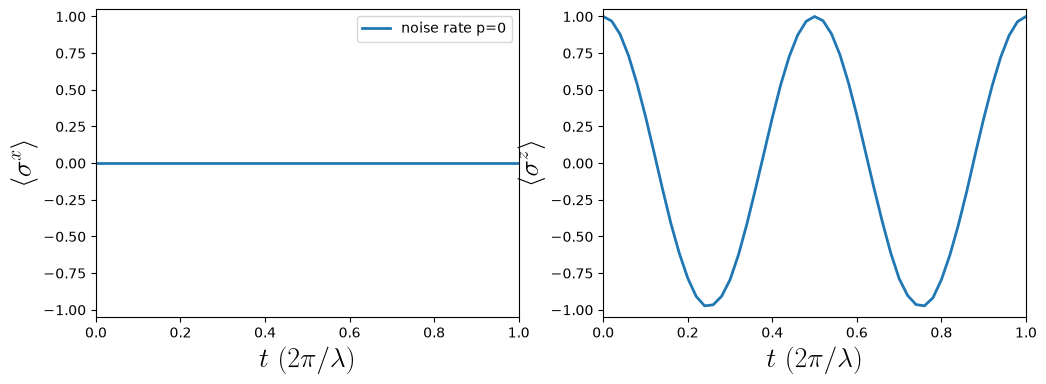

In [7]:
import matplotlib.pyplot as plt

fontsize = 20

#tarray = np.linspace(0,t_tot,N)
fig, ax = plt.subplots(1,2,figsize=(12,4))
for i, p  in enumerate(p_error):
    ax[0].plot(sampling_t_list/(2*np.pi/lam),sigma_x_expectation[i],linewidth=2,label=f"noise rate p={p}")
    ax[1].plot(sampling_t_list/(2*np.pi/lam),sigma_z_expectation[i],linewidth=2,label=f"noise rate p={p}")

ax[0].set_ylabel(r'$\langle\sigma^x\rangle$',fontsize=fontsize,usetex=True);
ax[1].set_ylabel(r'$\langle\sigma^z\rangle$',fontsize=fontsize,usetex=True);

ax[0].set_xlabel(r'$t$ $(2\pi/\lambda)$',fontsize=fontsize,usetex=True);
ax[1].set_xlabel(r'$t$ $(2\pi/\lambda)$',fontsize=fontsize,usetex=True);

ax[0].legend(loc='upper right')

ax[0].set_xlim([0,1]);
ax[1].set_xlim([0,1]);
ax[0].set_ylim([-1.05,1.05]);
ax[1].set_ylim([-1.05,1.05]);

## Calculating the spectrum

Number of steps:  157


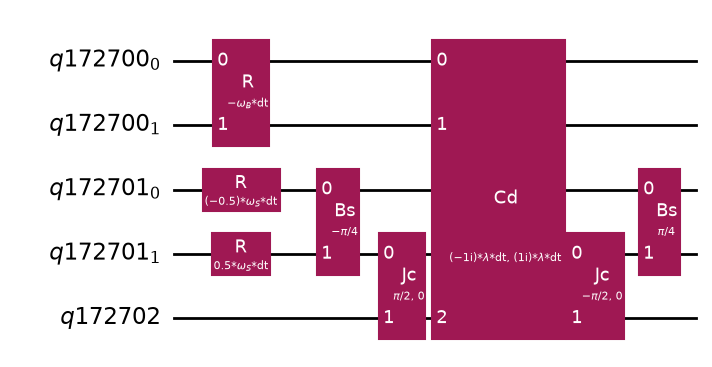

In [18]:
# Define computational parameters 

num_qubits_per_qumode = 2 # Cutoff of the qumode's Fock space: 2^num_qubits_per_qumode
dfreq = 0.02
t_tot = 1.0/dfreq*np.pi*2.0 # total time 
dt = 1.25 # timestep
epsilon = 0.001 # kick strength
N = int(t_tot/2.0)
sampling_t_list = np.linspace(0, t_tot, N+1, endpoint = True)
print("Number of steps: ", N)

# Create new circuits for basilen and kicked dynamics
boson = bosonic_qiskit.QumodeRegister(num_qumodes=1, num_qubits_per_qumode=num_qubits_per_qumode) # qumode for the boson
spin = bosonic_qiskit.QumodeRegister(num_qumodes=2, num_qubits_per_qumode=1) # 2 qumodes for dual rail encoding of the spin. spin[0]: up, spin[1]: down
ancilla = qiskit.QuantumRegister(1) # Ancilla qubit needed for implementing the U_{LM}

circuit = bosonic_qiskit.CVCircuit(boson,spin,ancilla)
circuit_kick = bosonic_qiskit.CVCircuit(boson,spin,ancilla)

# Pretty print circuit 
circuit_print = circuit.copy()
eiht(circuit_print, boson, spin, ancilla, Parameter('$\omega_S$'), Parameter('$\omega_B$'), Parameter('$\lambda$'), Parameter('dt'))
fig = circuit_print.draw(output="mpl")
display(fig)


# |down> = |0_up, 1_down>
circuit.cv_initialize(1, spin[1])
circuit_kick.cv_initialize(1, spin[1])

# Initialize state with delta kick
circuit_kick = sigma_x_kick(circuit_kick, boson, spin, ancilla, epsilon)

# timestep list for each sampling point
dt_list = []
for t in sampling_t_list:
    li = [dt for i in range(int(t/dt))]
    if len(li)*dt < t:
        li = li + [t - len(li)*dt]
    dt_list.append(li)
#print(dt_list)
#print(len(dt_list))

# Build list of circuits for the points in the time series
circuit_list_kick = []
for li in dt_list:
    circuit_list_kick.append(trotterise(circuit_kick.copy(), boson, spin, ancilla, omega_A, omega_C, lam, N, li))

In [19]:
# Define matrices of the observables
I_boson = circuit.ops.get_eye(boson.cutoff).toarray()
I_ancilla = circuit.ops.get_eye(2).toarray()
I_2 = np.eye(2)
n_2 = np.diag([0, 1])
s_minus_2 = np.array([[0, 1], [0, 0]])
s_plus_2 = np.array([[0, 0], [1, 0]])
sigmaz_spin =  np.kron(I_2, n_2) - np.kron(n_2, I_2)
sigmax_spin =  np.kron(s_minus_2, s_plus_2) + np.kron(s_plus_2, s_minus_2)
sigmaz = np.kron(I_ancilla, np.kron(sigmaz_spin, I_boson))
sigmax = np.kron(I_ancilla, np.kron(sigmax_spin, I_boson))

observable = [SparsePauliOp.from_operator(sigmax)] # Converting sigmax matrix to Pauli strings
params = [] # circuit parameters


sigma_x_expectation_baseline = []
sigma_x_expectation_kick = []

estimator = Estimator()

sigma_x_traj_kick = estimate_traj(circuit_list_kick, observable, params, estimator)

step 0
step 10
step 20
step 30
step 40
step 50
step 60
step 70
step 80
step 90
step 100
step 110
step 120
step 130
step 140
step 150


In [20]:
#Dividing by kick strength:
sigma_x_traj_kick = sigma_x_traj_kick/epsilon

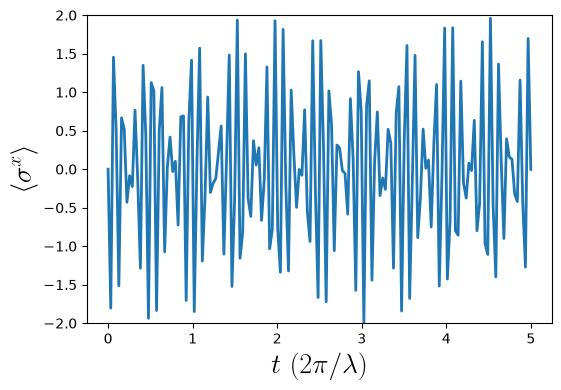

In [22]:
fontsize = 20

fig, ax = plt.subplots(1,1,figsize=(6,4))

ax.plot(sampling_t_list/(2*np.pi/lam),sigma_x_traj_kick,linewidth=2)

ax.set_ylabel(r'$\langle\sigma^x\rangle$',fontsize=fontsize,usetex=True);
ax.set_xlabel(r'$t$ $(2\pi/\lambda)$',fontsize=fontsize,usetex=True);

#ax.legend(loc='upper right')
ax.set_ylim([-2,2]);


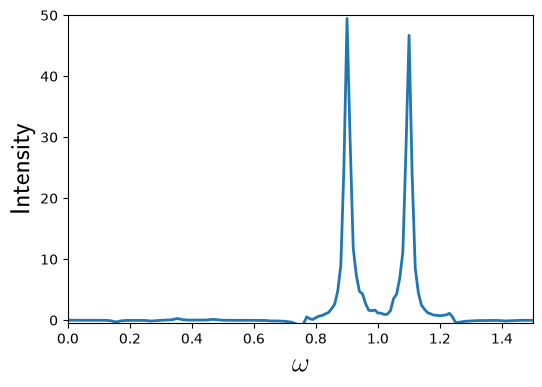

In [23]:
#Fourier transform the sigma_x signal. This is the dipole-dipole autocorrelation function C_list
freq_list, C_list, _ = two_sided_ft(sigma_x_traj_kick[:,0], 2.0, window=("exp", 100.0), zero_pad_to=2*157, angular_freq=True)

# Calculating absorption intensity from the freq-domain 
int_list = -np.imag(C_list)

#Plotting the spectrum

fig, ax = plt.subplots(1,1,figsize=(6,4))
fontsize = 20

ax.plot(freq_list,int_list,linewidth=2)

ax.set_ylabel(r'Intensity',fontsize=fontsize,usetex=True);
ax.set_xlabel(r'$\omega$',fontsize=fontsize,usetex=True);

#ax.legend(loc='upper right')
ax.set_ylim(-0.5,50);
ax.set_xlim(0,1.5);

In [1]:
def eiht(circuit, boson, spin, ancilla, omega_A, omega_C, lam, dt):
    # Appending each gate to the circuit
    
    # U_L = exp(-i omega_C a^\dag a t): rotation for the boson
    circuit.cv_r(-omega_C*dt,boson[0])

    # U_M = exp(-i omega_A \sigma_z/2 t) = exp(-i omega_A u^\dag u t) * exp( i omega_A d^\dag d t): rotation for the spin
    circuit.cv_r(-0.5*omega_A*dt,spin[0])
    circuit.cv_r(+0.5*omega_A*dt,spin[1])

    # Implementing U_LM = exp(-i lambda \sigma_z (a^\dag +a) t) for the spin and the boson
    
    # Note that the controlled displacement gate uses sigma_z for the spin, not sigma_x, so we
    # rotate the spin's X component into Z, using a beamsplitter
    circuit.cv_bs(-math.pi/4, spin[0], spin[1])
    
    # Swap the state of the "down spin" bosonic mode with the ancilla qubit using a Jaynes-Cummings gate
    circuit.cv_jc(math.pi/2, 0, spin[1], ancilla[0])
    
    # U_LM = exp(-i lambda \sigma_z (a^\dag +a) t) as a controlled displacement for the ancilla qubit and the boson
    circuit.cv_c_d(-1j*lam*dt,boson[0],ancilla[0])

    # Swap the state of the "down spin" bosonic mode with the ancilla qubit using a Jaynes-Cummings gate
    circuit.cv_jc(-math.pi/2, 0, spin[1], ancilla[0])
    
    # Rotate back the spin's Z component into X using a beamsplitter
    circuit.cv_bs(+math.pi/4, spin[0], spin[1])

    return circuit

def trotterise(circuit, boson, spin, ancilla, omega_A, omega_C, lam, N, dt_list):
    # Builds a trotterised circuit for the time steps given in dt_list
    # Returns: list of circuits 
    
    # Trotterised time evolution
    for dt in dt_list:
        # Implement the circuit, add gates for time evolution 
        eiht(circuit, boson, spin, ancilla, omega_A, omega_C, lam, dt)

    return circuit

def estimate(circuit, observable, params, estimator):
    # Computing observables with the Estimator functionality
    
    # The circuit needs to be transpiled to the AerSimulator target
    pass_manager = generate_preset_pass_manager(1, AerSimulator())
    isa_circuit = pass_manager.run(circuit)
    pub = (isa_circuit, observable, params)
    
    job = estimator.run([pub])
    result = job.result()
    pub_result = result[0]
    value = pub_result.data.evs
    
    return value 

def sigma_x_kick(circuit, boson, spin, ancilla, epsilon):
    # exp(- i epsilon sigma_x) = exp(-i epsilon (u^\dag d + u d^\dag)) kick
    
    circuit.cv_bs(-1j*epsilon, spin[0], spin[1])

    return circuit

def estimate_traj(circuit_list, observable, params, estimator):
    res = []
    for i, c in enumerate(circuit_list):
        if i%10==0:
            print("step", i)
        value = estimate(c, observable, params, estimator)
        res.append(value)

    return np.asarray(res)

def two_sided_ft(x_t, dt, window=("exp", 100.0), zero_pad_to=None,
                          angular_freq=True, shift=True):
    x_t = np.asarray(x_t)
    N = len(x_t)
    t = np.arange(N) * dt

    if window is None or window == "none":
        win = np.ones(N)
    elif isinstance(window, tuple) and window[0] == "exp":
        tau = float(window[1])
        win = np.exp(-t / tau)
    elif window == "hann":
        win = np.hanning(N)
    elif window == "hamming":
        win = np.hamming(N)
    else:
        raise ValueError("Unknown window.")

    x_win = x_t * win

    if zero_pad_to is None:
        M = N
    else:
        M = int(zero_pad_to)
        if M < N:
            raise ValueError("zero_pad_to must be >= len(x_t)")
        x_win = np.pad(x_win, (0, M - N), mode="constant")

    # Computes dt * sum_n x_n exp(+i 2πkn/M)
    X = dt * M * np.fft.ifft(x_win)

    freq = np.fft.fftfreq(M, d=dt)
    w = 2*np.pi*freq if angular_freq else freq

    if shift:
        X = np.fft.fftshift(X)
        w = np.fft.fftshift(w)

    return w, X, x_win